In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [7]:
df = pd.read_csv("C:/Users/mestr/Downloads/archive (13)/sales_data_sample.csv", encoding="latin1")
df.head()


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [8]:
X = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES']]
X = X.dropna()

In [9]:
wcss = []

for i in range(1, 11):
    km = KMeans(n_clusters=i, random_state=42)
    km.fit(X)
    wcss.append(km.inertia_)

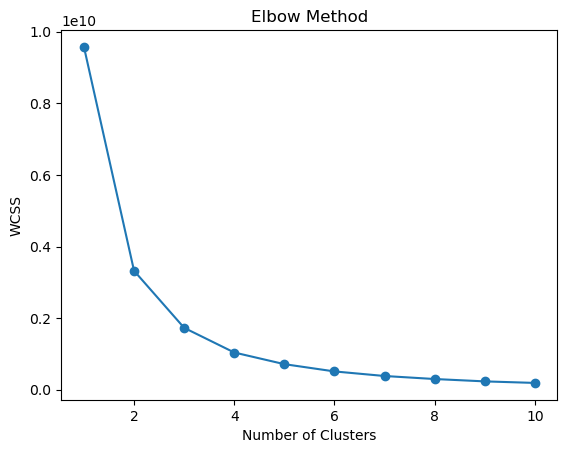

In [10]:
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [11]:
km = KMeans(n_clusters=3, random_state=42)
y_pred = km.fit_predict(X)

print(y_pred)

[0 0 1 ... 1 0 0]


In [14]:
sc = StandardScaler()

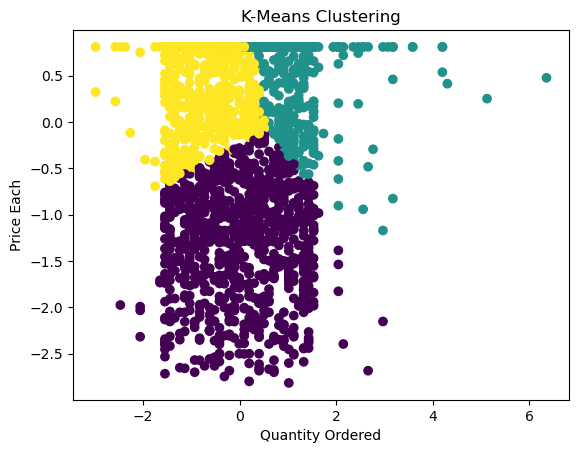

In [15]:
X = sc.fit_transform(df[['QUANTITYORDERED', 'PRICEEACH', 'SALES']].dropna())

km = KMeans(n_clusters=3, random_state=42)
y_pred = km.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=y_pred)
plt.xlabel("Quantity Ordered")
plt.ylabel("Price Each")
plt.title("K-Means Clustering")
plt.show()

In [16]:
print("Cluster Centers:")
print(km.cluster_centers_)

Cluster Centers:
[[ 0.00340709 -1.31519107 -0.83846133]
 [ 0.89846585  0.64278204  1.10107381]
 [-0.79188456  0.55612886 -0.2525054 ]]
